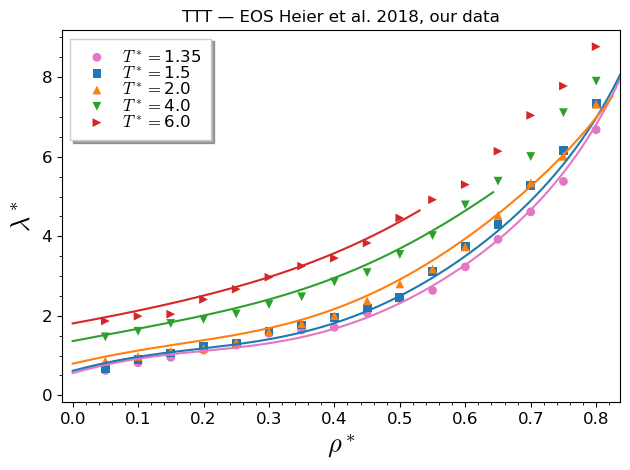

MAPE for rho* <= 0.8; equal weight per MD point.


T*,MAPE TTT (%)
1.35,6.4
1.5,6.6
2,7.7
4,5.2
6,4.0


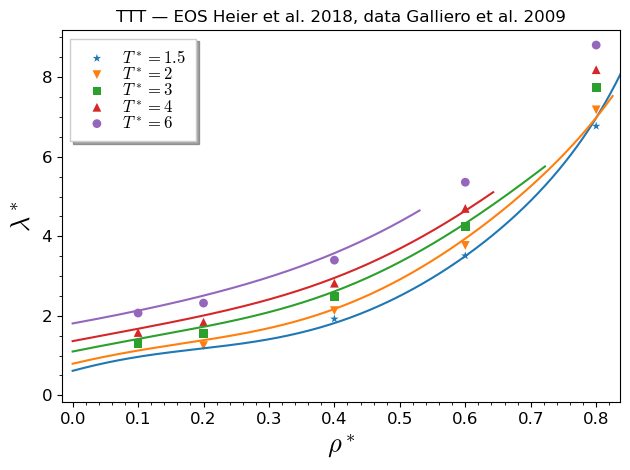

MAPE for rho* <= 0.8; equal weight per MD point.


T*,MAPE TTT (%)
1.5,2.9
2,5.0
3,7.7
4,7.0
6,4.9


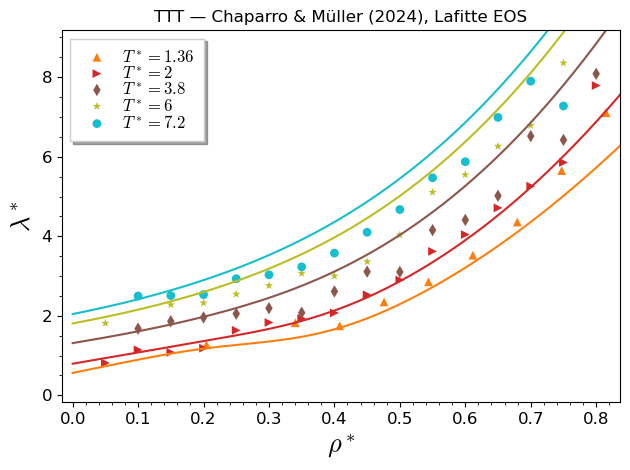

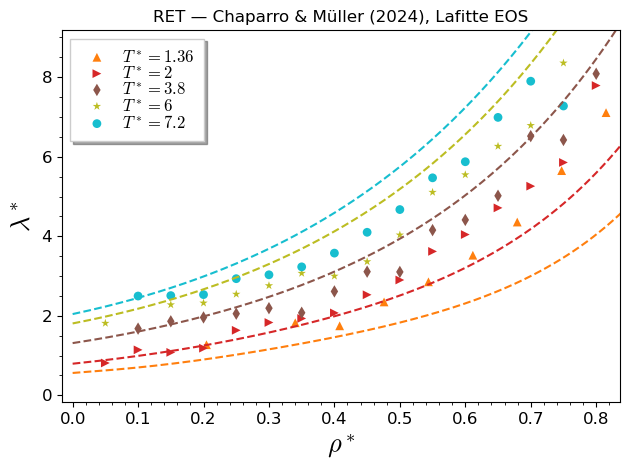

MAPE for rho* <= 0.8; equal weight per MD point.


T*,MAPE RET (%),MAPE TTT (%)
1.36,29,8.8
2,14,6.6
3.8,12,14
6,19,15
7.2,20,14


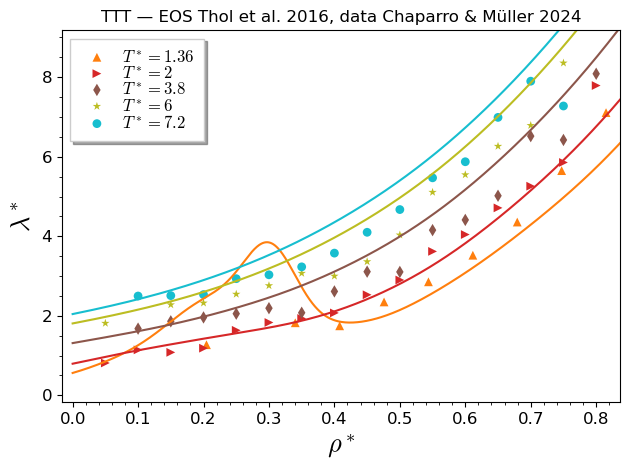

MAPE for rho* <= 0.8; equal weight per MD point.


T*,MAPE RET (%),MAPE TTT (%)
1.36,29,28
2,14,7.5
3.8,12,13
6,19,14
7.2,20,13


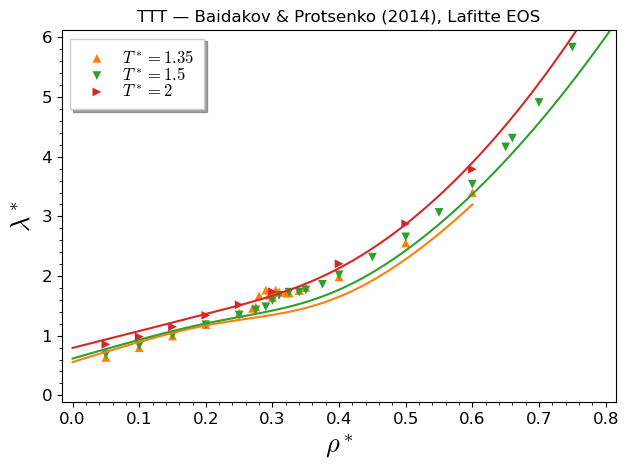

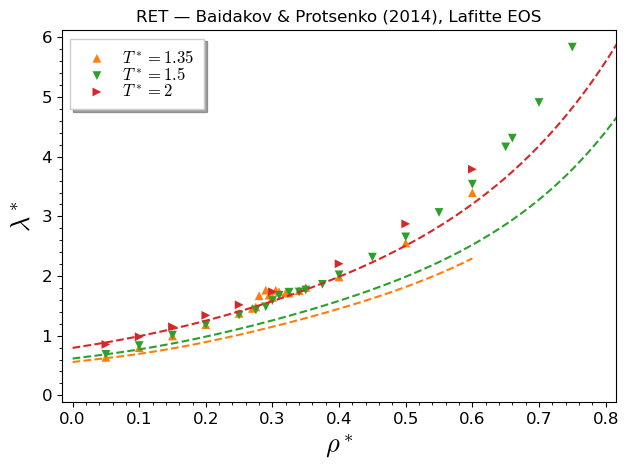

MAPE for rho* <= 0.8; equal weight per MD point.


T*,MAPE RET (%),MAPE TTT (%)
1.35,27,15
1.5,22,8.8
2,9.1,4.2


In [1]:
# Thermal conductivity of LJTS and full LJ fluids.
# Run this single cell with a SageMath kernel.
# Display seven figures and five MAPE tables; save each figure as PDF.
# TTT: Thermodynamic Transport Theory. RET: Revised Enskog Theory.
# All quantities are in reduced LJ units; c_V is per particle in units of k_B.
# rho* = number_density*sigma^3; lambda* = lambda*sigma^2*sqrt(m/epsilon)/k_B.
# Plot lambda* directly: no dilute-gas normalization or Rosenfeld scaling.
import math
from functools import lru_cache

var('T rho tau delta')

# 1. Dilute-gas conductivity: Fokin collision integral (Meier, pp. 194-195).
bb = [0.310810, -0.171211, -0.715805, 2.48678, -1.78317, 0.394405]
Omega22 = exp(-log(T)/6 + log(17/18) + sum(bb[i]*sqrt(T)^(-i) for i in range(6)))
lid = 75/64*sqrt(T/n(pi))/Omega22

def conductivity(cv, Z):
    Gamma = diff(rho*Z, rho)
    # lambda/lambda_id = (2/5)*sqrt(2*c_V/3)*(-T*c_V,T + 2*rho*c_V,rho + (T*Gamma),T + c_V).
    return lid * 2/5 * sqrt(2/3*cv) * (
        -T*diff(cv, T) + 2*rho*diff(cv, rho) + diff(T*Gamma, T) + cv)

def thol_properties(poly, expo, gauss, Tc, rhoc):
    # Coefficient rows: (n,t,d), (n,t,d,l), (n,t,d,eta,beta,gamma,epsilon).
    alpha = (sum(n*delta^d*tau^t for n,t,d in poly)
             + sum(n*delta^d*tau^t*exp(-delta^l) for n,t,d,l in expo)
             + sum(n*delta^d*tau^t*exp(-eta*(delta-eps)^2-beta*(tau-gam)^2)
                   for n,t,d,eta,beta,gam,eps in gauss))
    A01 = delta*diff(alpha, delta)
    A20 = tau^2*diff(alpha, tau, 2)
    state = {tau: Tc/T, delta: rho/rhoc}
    # Return c_V, the compressibility factor Z, and pressure.
    return ((3/2-A20).subs(state), (1+A01).subs(state),
            (rho*T*(1+A01)).subs(state))

# 2. PeTS EOS: Heier et al. (2018), LJ truncated and shifted at 2.5 sigma.
c1 = RealNumber('0.127112544')
c2 = RealNumber('3.052785558')
a_ = [0.690603404, 1.189317012, 1.265604153, -24.34554201, 93.67300357, -157.8773415, 96.93736697]
b_ = [0.664852128, 2.10733079, -9.597951213, -17.37871193, 30.17506222, 209.3942909, -353.2743581]
d      = 1 - c1*exp(-c2/T)
eta    = (pi.n()/6.)*rho*d^3
a_hs   = eta*(4. - 3.*eta)/(1-eta)^2
I1     = sum(a_[i]*eta^i for i in range(7))
I2     = sum(b_[i]*eta^i for i in range(7))
zeta   = (8.*eta - 2.*eta^2)/(1-eta)^4
a1T    = -2*pi.n()*rho*I1/T
a2T    = -pi.n()*rho*I2/((1+zeta)*T^2)
a_res  = (a_hs + a1T + a2T)
cvh = 3/2 - T^2*diff(a_res, T, 2) - 2*T*diff(a_res, T)
Zh = 1 + rho*diff(a_res, rho)
lambda_h = conductivity(cvh, Zh)


# 3. Thol et al. (2014), LJTS: pressure used to set the Heier plotting domain.
poly = [(0.0156060840,1.000,4), (1.7917527000,0.304,1), (-1.9613228000,0.583,1),
        (1.3045604000,0.662,2), (-1.8117673000,0.870,2), (0.1548399700,0.870,3)]
expo = [(-0.4751098200,1.286,1,1), (-0.5842280700,1.960,1,2), (-0.5060736400,2.400,3,2),
        (0.1163964400,1.700,2,1), (-0.2009241200,3.000,2,2), (-0.0948852040,1.250,5,1)]
gaus = [(0.0094333106,3.600,1,4.70,20.0,1.0,0.55), (0.3044462800,2.080,1,1.92,0.77,0.5,0.70),
        (-0.0010820946,5.240,2,2.70,0.50,0.8,2.00), (-0.0996933910,0.960,3,1.49,0.80,1.5,1.14),
        (0.0091193522,1.360,3,0.65,0.40,0.7,1.20), (0.1297054300,1.655,2,1.73,0.43,1.6,1.31),
        (0.0230360300,0.900,1,3.70,8.00,1.3,1.14), (-0.0826710730,0.860,2,1.90,3.30,0.6,0.53),
        (-2.2497821000,3.950,3,13.20,114.0,1.3,0.96)]
_, _, pt2 = thol_properties(poly, expo, gaus, 1.086, 0.319)


# 4. Thol et al. (2016): full Lennard-Jones EOS.
poly = [
    (0.005208073, 1.0, 4),
    (2.186252, 0.32, 1),
    (-2.161016, 0.505, 1),
    (1.4527, 0.672, 2),
    (-2.041792, 0.843, 2),
    (0.18695286, 0.898, 3)
]

expo = [
    (-0.090988445, 1.294, 5, 1),
    (-0.4974561, 2.59, 2, 2),
    (0.10901431, 1.786, 2, 1),
    (-0.80055922, 2.77, 3, 2),
    (-0.568839, 1.786, 1, 2),
    (-0.6208625, 1.205, 1, 1)
]

gauss = [
    (-1.4667177, 2.83, 1, 2.067, 0.625, 0.71, 0.2053),
    (1.891469, 2.548, 1, 1.522, 0.638, 0.86, 0.409),
    (-0.1383701, 4.65, 2, 8.82, 3.91, 1.94, 0.6),
    (-0.3869645, 1.385, 3, 1.722, 0.156, 1.48, 1.203),
    (0.1265702, 1.46, 3, 0.679, 0.157, 1.49, 1.829),
    (0.605781, 1.351, 2, 1.883, 0.153, 1.945, 1.397),
    (1.179189, 0.66, 1, 3.925, 1.16, 3.02, 1.39),
    (-0.47732679, 1.496, 2, 2.461, 1.73, 1.11, 0.539),
    (-9.9218575, 1.83, 3, 28.2, 383, 1.17, 0.934),
    (-0.5747932, 1.616, 1, 0.753, 0.112, 1.33, 2.369),
    (0.003772923, 4.97, 1, 0.82, 0.119, 0.24, 2.43)
]
cvt, Zt, _ = thol_properties(poly, expo, gauss, 1.32, 0.31)
lambda_t = conductivity(cvt, Zt)


# 5. Lafitte et al. (2013), SAFT-VR Mie, monomeric LJ (12-6).
# J. Chem. Phys. 139, 154504; DOI: 10.1063/1.4819786.
# Full LJ: m=1, sigma=epsilon=k_B=1; no chain or association contributions.
# Equations (7), (10)-(11), (16)-(20), (28)-(29), (33)-(34), (36), (39)-(41).
def bh_integrand(r, temperature, order):
    # Differentiate the BH integral analytically, then integrate numerically.
    if r <= 1.e-12:
        return 1.0 if order == 0 else 0.0
    q = 4.0*(r**(-12) - r**(-6))/temperature
    if q > 700.0:
        return 1.0 if order == 0 else 0.0
    weight = math.exp(-q)
    if order == 0:
        return -math.expm1(-q)
    if order == 1:
        return -q*weight/temperature
    if order == 2:
        return (2*q - q**2)*weight/temperature**2
    return (-6*q + 6*q**2 - q**3)*weight/temperature**3

@lru_cache(maxsize=None)
def bh_diameter_derivatives(temperature):
    # Return d(T), d'(T), d''(T), d'''(T); double-precision quadrature.
    temperature = float(temperature)
    if temperature <= 0:
        raise ValueError("The BH diameter requires T > 0.")
    return tuple(numerical_integral(
        lambda r: bh_integrand(r, temperature, order), 0.0, 1.0,
        eps_abs=1.e-12, eps_rel=1.e-12)[0] for order in range(4))

# Keep d(T) symbolic during differentiation to retain all temperature terms.
d_lafitte = function('d_lafitte')
dl = d_lafitte(T)
eta_l = n(pi)/6*rho*dl^3
x0_l = 1/dl
eta_sigma_l = n(pi)/6*rho
C_l, alpha_l = 4, 8/9

# Table II: one row per f_i, with coefficients ordered n=0,...,6.
phi_l = [
    (7.5365557, -37.60463, 71.745953, -46.83552, -2.467982, -0.50272, 8.0956883),
    (-359.44, 1825.6, -3168.0, 1884.2, -0.82376, -3.1935, 3.7090),
    (1550.9, -5070.1, 6534.6, -3288.7, -2.7171, 2.0883, 0),
    (-1.19932, 9.063632, -17.9482, 11.34027, 20.52142, -56.6377, 40.53683),
    (-1911.28, 21390.175, -51320.7, 37064.54, 1103.742, -3264.61, 2556.181),
    (9236.9, -129430, 357230, -315530, 1390.2, -4518.2, 4241.6),
]
f_l = [sum(row[j]*alpha_l^j for j in range(4)) /
       (1 + sum(row[j]*alpha_l^(j-3) for j in range(4, 7))) for row in phi_l]
mvt_l = [
    (0.81096, 1.7888, -37.578, 92.284),
    (1.0205, -19.341, 151.26, -463.50),
    (-1.9057, 22.845, -228.14, 973.92),
    (1.0885, -6.1962, 106.98, -677.64),
]

def lafitte_sutherland(exponent):
    # Return a_1^S(eta; exponent) + B(eta; exponent).
    coefficients = [sum(row[j]/exponent^j for j in range(4)) for row in mvt_l]
    eta_eff = sum(coefficients[j]*eta_l^(j+1) for j in range(4))
    a1s = -12*eta_l/(exponent-3)*(1-eta_eff/2)/(1-eta_eff)^3
    integral_i = (1-x0_l^(3-exponent))/(exponent-3)
    integral_j = ((1-x0_l^(4-exponent))/(exponent-4) - integral_i)
    B = 12*eta_l*((1-eta_l/2)*integral_i -
                  9*eta_l*(1+eta_l)*integral_j/2)/(1-eta_l)^3
    return a1s + B

s_l = {exponent: lafitte_sutherland(exponent) for exponent in [6, 12, 18, 24]}
ahs_l = (4*eta_l-3*eta_l^2)/(1-eta_l)^2
khs_l = (1-eta_l)^4/(1+4*eta_l+4*eta_l^2-4*eta_l^3+eta_l^4)
chi_l = f_l[0]*eta_sigma_l + f_l[1]*eta_sigma_l^5 + f_l[2]*eta_sigma_l^8
a1_l = C_l*(x0_l^6*s_l[6] - x0_l^12*s_l[12])
a2_l = C_l^2/2*khs_l*(1+chi_l)*(
    x0_l^12*s_l[12] - 2*x0_l^18*s_l[18] + x0_l^24*s_l[24])
a3_l = -f_l[3]*eta_sigma_l*exp(f_l[4]*eta_sigma_l + f_l[5]*eta_sigma_l^2)
ares_l = ahs_l + a1_l/T + a2_l/T^2 + a3_l/T^3
fexl = T*ares_l
cvl = 3/2 - T*diff(fexl, T, 2)
Zl = 1 + rho*diff(ares_l, rho)
lambda_l = conductivity(cvl, Zl)

bh_terms = [dl] + [diff(dl, T, order) for order in range(1, 4)]

def temperature_slice(expression, temperature):
    # Substitute BH derivatives only AFTER all symbolic thermodynamic derivatives.
    # Use this helper also to evaluate cvl, Zl, fexl, or lambda_l at fixed T.
    if expression.has(dl):
        values = bh_diameter_derivatives(float(temperature))
        for term, value in reversed(list(zip(bh_terms, values))):
            expression = expression.subs({term: value})
    return expression.subs({T: temperature})


# 6. Revised Enskog theory for full LJ, Jervell & Wilhelmsen (2023).
# DOI: 10.1063/5.0149865, Eqs. (7), (13), (33), and (38)-(40).
# First Sonine approximation (N=2), using Fokin Omega22 as in the TTT dilute limit.
# The Lafitte RDF is evaluated at sigma=1, NOT at the BH or collision diameter.
# Lafitte et al. (2013), Eqs. (43), (46)-(50), and (63)-(66).
eta = eta_l
k0_ret = -log(1-eta)+(42*eta-39*eta^2+9*eta^3-2*eta^4)/(6*(1-eta)^3)
k1_ret = (eta^4+6*eta^2-12*eta)/(2*(1-eta)^3)
k2_ret = -3*eta^2/(8*(1-eta)^2)
k3_ret = (-eta^4+3*eta^2+3*eta)/(6*(1-eta)^3)
g0_ret = exp(k0_ret+k1_ret*x0_l+k2_ret*x0_l^2+k3_ret*x0_l^3)
g1_ret = (3*diff(a1_l, rho) + C_l/rho*(
    12*x0_l^12*s_l[12]-6*x0_l^6*s_l[6]))/(2*n(pi)*dl^3)
a2_mca_ret = C_l^2/2*khs_l*(
    x0_l^12*s_l[12]-2*x0_l^18*s_l[18]+x0_l^24*s_l[24])
g2_mca_ret = (3*diff(a2_mca_ret, rho) + C_l^2*khs_l/rho*(
    -12*x0_l^24*s_l[24]+18*x0_l^18*s_l[18]-6*x0_l^12*s_l[12]))/(2*n(pi)*dl^3)
gamma_ret = 10*(1-tanh(10*(0.57-alpha_l)))*eta_sigma_l*(exp(1/T)-1)*exp(
    -6.7*eta_sigma_l-8*eta_sigma_l^2)
g_ret = g0_ret*exp((g1_ret/T+(1+gamma_ret)*g2_mca_ret/T^2)/g0_ret)

def ret_bisect(f, lower, upper, tolerance=1.e-11):
    left = f(lower)
    if left * f(upper) > 0:
        raise ValueError("RET root is not bracketed.")
    for _ in range(80):
        middle = (lower + upper)/2.
        value = f(middle)
        if upper-lower < tolerance or value == 0:
            return middle
        if left*value > 0:
            lower, left = middle, value
        else:
            upper = middle
    raise RuntimeError("RET root did not converge.")

def ret_simpson(f, lower, upper, panels):
    step = (upper-lower)/panels
    return step/3.*(f(lower)+f(upper) + sum(
        (4 if i % 2 else 2)*f(lower+i*step) for i in range(1, panels)))

def ret_closest_approach(energy, impact):
    # Inner scattering branch, used only before the first zero of deflection.
    def radial(r):
        return 1.-4./energy*(r**(-12)-r**(-6))-(impact/r)**2
    head_on = ((1.+math.sqrt(1.+energy))/2.)**(-1./6.)
    if impact == 0:
        return head_on
    lower = head_on
    for i in range(1, 401):
        upper = head_on+i*.005
        if radial(upper) >= 0:
            return ret_bisect(radial, lower, upper)
        lower = upper
    raise RuntimeError("Could not bracket the repulsive scattering branch.")

def ret_deflection(energy, impact, panels=256):
    if impact == 0:
        return math.pi
    closest = ret_closest_approach(energy, impact)
    a, c = 4./(energy*closest**12), 4./(energy*closest**6)
    b2 = (impact/closest)**2
    # u=R/r=1-t^2 removes the square-root endpoint singularity.
    # Factor 1-u^k explicitly to avoid cancellation near t=0.
    def integrand(t):
        u = 1.-t*t
        denominator = a*sum(u**j for j in range(12)) \
                      - c*sum(u**j for j in range(6)) + b2*(1.+u)
        if denominator <= 0:
            raise ValueError("Orbiting trajectory outside the deflecting branch.")
        return 2.*impact/closest/math.sqrt(denominator)
    return math.pi-2.*ret_simpson(integrand, 0., 1., panels)

@lru_cache(maxsize=None)
def ret_collision_diameter(temperature, panels=256):
    # Jervell & Wilhelmsen (2023), Eqs. (38)-(40), reduced LJ units.
    # Mean relative speed gives E*=T*/pi; this diameter is NOT the BH diameter.
    energy = float(temperature)/math.pi
    lower = 0.
    for i in range(1, 151):
        upper = i*.01
        if ret_deflection(energy, upper, panels) <= 0:
            break
        lower = upper
    else:
        raise RuntimeError("Could not bracket the zero-deflection impact parameter.")
    impact_zero = ret_bisect(lambda b: ret_deflection(energy, b, panels), lower, upper)
    return ret_simpson(lambda b: ret_closest_approach(energy, b),
                       0., impact_zero, panels)/impact_zero


@lru_cache(maxsize=None)
def ret_isotherm(temperature):
    temperature = float(temperature)
    diameter = ret_collision_diameter(temperature)
    rdf = temperature_slice(g_ret, temperature)
    dilute = float(lid(T=temperature))
    def evaluate(density):
        density = float(density)
        if density < 0:
            raise ValueError("RET requires nonnegative density.")
        if density == 0:
            return dilute
        contact = float(rdf(rho=density))
        K = 1.+2.*math.pi/5.*density*diameter**3*contact
        # Pure-component reduction of Eq. (13): kinetic + collisional transport.
        value = dilute*K**2/contact + 2./3.*math.sqrt(math.pi*temperature)*(
            density**2*diameter**4*contact)
        if not math.isfinite(value) or value <= 0 or contact <= 0:
            raise ValueError("Invalid RET conductivity or contact RDF.")
        return value
    return evaluate

# 7. Simulation data: each pair is [rho*, lambda*].
# Galliero et al. (2009).
condG6 = [
    [0.1, 2.07], [0.2, 2.32], [0.4, 3.4], [0.6, 5.36],
    [0.8, 8.81], [0.9, 11.31], [1.0, 14.78],
]
condG4 = [
    [0.1, 1.58], [0.2, 1.84], [0.4, 2.82], [0.6, 4.7],
    [0.8, 8.19], [0.9, 10.79], [1.0, 14.03],
]
condG3 = [
    [0.1, 1.3], [0.2, 1.56], [0.4, 2.48], [0.6, 4.25],
    [0.8, 7.74], [0.9, 10.45], [1.0, 13.5],
]
condG2 = [
    [0.2, 1.25], [0.4, 2.13], [0.6, 3.77], [0.8, 7.18],
    [0.9, 9.75], [1.0, 12.74],
]
condG15 = [
    [0.4, 1.92], [0.6, 3.51], [0.8, 6.77], [0.9, 9.32],
]
TG = [1.5, 2, 3, 4, 6]

# Chaparro & Muller (2024), DOI: 10.1021/acs.jpcb.3c06813.
# Mie (12,6), cutoff 5 sigma, no long-range corrections; original supplied records.
lambdaCM = {
    1.36: [
        [0.204518, 1.272723269544927], [0.340197, 1.8247423305548032], [0.408037, 1.7479396813586003], [0.475876, 2.3487157237307237],
        [0.543715, 2.8548860645960827], [0.611555, 3.5235430345967047], [0.679394, 4.358221609425745], [0.747234, 5.651326425513695],
        [0.815073, 7.110176980728024], [0.882913, 8.497016366854176],
    ],
    2: [
        [0.05, 0.8130890725044448], [0.1, 1.1431745541630345], [0.15, 1.0805462312288705], [0.2, 1.185702647906419],
        [0.25, 1.6353188365194165], [0.3, 1.8319010169253416], [0.35, 1.9331681480179643], [0.4, 2.072588571981489],
        [0.45, 2.5288450606639348], [0.5, 2.9001968278572643], [0.55, 3.6199377358090743], [0.6, 4.043824946128447],
        [0.65, 4.7144443036799855], [0.7, 5.260537493880133], [0.75, 5.856750601266866], [0.8, 7.791378432191556],
        [0.85, 8.749288753651363], [0.9, 10.765528689404375], [0.95, 11.695991602636376], [1, 13.958974250312952],
    ],
    3.8: [
        [0.15, 1.8614058830315616], [0.1, 1.6770650978987596], [0.2, 1.959273258018855], [0.25, 2.0529363455225953],
        [0.3, 2.1914591766908247], [0.35, 2.0765161350250043], [0.4, 2.613317757433413], [0.45, 3.109918452473242],
        [0.5, 3.103412556683267], [0.55, 4.154942531246878], [0.6, 4.411751645230106], [0.65, 5.019494256660012],
        [0.7, 6.519213569311275], [0.75, 6.422466564786166], [0.8, 8.087705753038783], [0.85, 9.869894827633386],
        [0.9, 11.507721445928397], [0.95, 12.3616489262012], [1, 13.851373078326988], [1.05, 16.027541831254023],
        [1.1, 16.889201116120738], [1.15, 21.42989213560584], [1.2, 21.099551939339086],
    ],
    6: [
        [0.05, 1.813338241731077], [0.15, 2.278971399196926], [0.2, 2.322481937229406], [0.25, 2.5445215638524257],
        [0.3, 2.7594843720959052], [0.35, 3.0703872500918528], [0.4, 2.999419774767458], [0.45, 3.362584624405861],
        [0.5, 4.034033610407173], [0.55, 5.1075589606743135], [0.6, 5.548942903293513], [0.65, 6.264931019440602],
        [0.7, 6.788564175734924], [0.75, 8.358969441743538], [0.8, 9.880999844604132], [0.85, 9.656220412411956],
        [0.9, 12.194627857299428], [0.95, 12.16632199141471], [1, 14.612346042910511], [1.05, 16.89275015459754],
        [1.1, 18.199047564527568], [1.15, 21.97700902283816], [1.2, 24.23186594029081],
    ],
    7.2: [
        [0.3, 3.031468219324184], [0.1, 2.4972401181202883], [0.15, 2.5081070275851975], [0.2, 2.5332260814504073],
        [0.25, 2.9336543744471792], [0.4, 3.576654941612468], [0.45, 4.100512914399521], [0.5, 4.672101938402435],
        [0.55, 5.470516697707442], [0.6, 5.8750126137257945], [0.65, 6.990453679448381], [0.7, 7.9005689779979],
        [0.8, 9.945040754750584], [0.85, 10.76269840221787], [0.9, 12.567145349492549], [0.95, 14.2968190791117],
        [1, 15.738870649921278], [1.05, 16.104468141922702], [1.1, 20.41306323932134], [1.15, 21.152559336804213],
        [1.2, 24.3650789356918], [0.35, 3.231144578393013], [0.75, 7.277040113283016],
    ],
}
TCM = [1.36, 2, 3.8, 6, 7.2]

# Ales simulation data.
CCalc150bis = [
    [0.05, 0.6715], [0.1, 0.8945], [0.15, 1.065], [0.2, 1.2425],
    [0.25, 1.308], [0.3, 1.601], [0.35, 1.7665], [0.4, 1.964],
    [0.45, 2.195], [0.5, 2.4625], [0.55, 3.119], [0.6, 3.734],
    [0.65, 4.292], [0.7, 5.281], [0.75, 6.162], [0.8, 7.344],
    [0.85, 8.363], [0.9, 10.42],
]
CCalc200 = [
    [0.05, 0.8582], [0.1, 0.9782], [0.15, 1.103], [0.2, 1.1826],
    [0.25, 1.331], [0.3, 1.598], [0.35, 1.799], [0.4, 2.0044],
    [0.45, 2.3762], [0.5, 2.802], [0.55, 3.178], [0.6, 3.733],
    [0.65, 4.525], [0.7, 5.345], [0.75, 6.012], [0.8, 7.321],
    [0.85, 8.361], [0.9, 9.722], [0.95, 10.927], [1.0, 12.577],
    [1.05, 14.384],
]
CCalc600 = [
    [0.05, 1.87], [0.1, 1.99], [0.15, 2.04], [0.2, 2.41],
    [0.25, 2.67], [0.3, 2.97], [0.35, 3.25], [0.4, 3.45],
    [0.45, 3.83], [0.5, 4.46], [0.55, 4.92], [0.6, 5.3],
    [0.65, 6.14], [0.7, 7.04], [0.75, 7.78], [0.8, 8.77],
    [0.85, 9.77], [0.9, 11.25], [1, 16.754], [1.05, 17.758],
    [0.95, 13.691],
]
CCalc135 = [
    [0.05, 0.625], [0.1, 0.819], [0.15, 0.955], [0.2, 1.137],
    [0.25, 1.262], [0.3, 1.561], [0.35, 1.643], [0.4, 1.711],
    [0.45, 2.077], [0.5, 2.436], [0.55, 2.638], [0.6, 3.231],
    [0.65, 3.923], [0.7, 4.614], [0.75, 5.38], [0.8, 6.68],
    [0.85, 7.51], [0.9, 8.51], [0.95, 10.43],
]
CCalc400 = [
    [0.05, 1.47], [0.1, 1.611], [0.15, 1.807], [0.2, 1.91],
    [0.25, 2.047], [0.3, 2.283], [0.35, 2.479], [0.4, 2.852],
    [0.45, 3.087], [0.5, 3.543], [0.55, 4.017], [0.6, 4.79],
    [0.65, 5.386], [0.7, 6.006], [0.75, 7.109], [0.8, 7.902],
    [0.85, 9.38], [0.9, 10.487], [0.95, 12.056],
]
TAl = [1.35, 1.5, 2, 4, 6]
lambdaAl = [CCalc135, CCalc150bis, CCalc200, CCalc400, CCalc600]


# Baidakov & Protsenko (2014), JCP 140, 214506; DOI: 10.1063/1.4880958.
# Table I: MD values [rho*, lambda*], cutoff 6.78 sigma, N=4000; no rescaling.
lambdaBaidakov = {
    1.35: [
        [0.050, 0.6368], [0.100, 0.7985], [0.150, 0.9946], [0.200, 1.185],
        [0.250, 1.374], [0.270, 1.457], [0.275, 1.481], [0.280, 1.669],
        [0.290, 1.763], [0.295, 1.680], [0.300, 1.641], [0.305, 1.763],
        [0.310, 1.735], [0.320, 1.717], [0.325, 1.715], [0.340, 1.757],
        [0.350, 1.808], [0.400, 1.985], [0.500, 2.553], [0.600, 3.397],
    ],
    1.5: [
        [0.050, 0.686], [0.100, 0.834], [0.150, 1.010], [0.200, 1.183],
        [0.250, 1.347], [0.275, 1.432], [0.290, 1.485], [0.300, 1.589],
        [0.310, 1.676], [0.325, 1.729], [0.340, 1.733], [0.350, 1.766],
        [0.375, 1.861], [0.400, 2.020], [0.450, 2.317], [0.500, 2.656],
        [0.550, 3.066], [0.600, 3.540], [0.650, 4.165], [0.660, 4.312],
        [0.700, 4.910], [0.750, 5.838], [0.800, 6.920], [0.850, 8.095],
        [0.900, 9.360], [0.950, 10.90], [1.000, 12.26], [1.050, 13.77],
        [1.075, 14.64], [1.100, 15.55], [1.120, 16.17], [1.130, 16.46],
    ],
    2.0: [
        [0.050, 0.854], [0.100, 0.982], [0.150, 1.150], [0.200, 1.341],
        [0.250, 1.517], [0.300, 1.737], [0.400, 2.206], [0.500, 2.875],
        [0.600, 3.791], [0.800, 7.204], [0.850, 8.394], [0.900, 9.833],
        [1.000, 12.86], [1.050, 14.58], [1.100, 16.25], [1.150, 18.02],
        [1.175, 18.90], [1.200, 19.74],
    ],
}

# 8. Shared plotting settings and selected EOS comparisons.
colors = ['#e377c2', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
          '#8c564b', '#7f7f7f', '#bcbd22', '#17becf', '#1a55FF']
markers = ['o', 's', '^', 'v', '>', '<', 'd', 'p', '*']
plot_options = dict(ymin=0, ymax=9, xmin=0, xmax=.82, frame=True, axes=False,
                    fontsize=12, legend_font_size=12,
                    axes_labels=[r'$\rho^*$', r'$\lambda^*$'])

# LJTS plotting cutoff: p*=6.8 from Thol (2014), used for Heier comparisons.
rho_max = {temp: find_root(pt2(T=temp)-6.8, 0.01, 1.5)
           for temp in set(TAl + TG)}

MAPE_RHO_MAX = 0.8

def format_mape(value):
    # Preserve two significant digits, including trailing zeros below 10.
    return format(float(value), '#.2g').rstrip('.') if value is not None else 'N/A'

def show_error_table(rows, include_ret):
    headers = (['T*', 'MAPE RET (%)', 'MAPE TTT (%)'] if include_ret
               else ['T*', 'MAPE TTT (%)'])
    result = table(rows, header_row=headers)
    mape_tables.append(result)
    print('MAPE; equal weight per MD point.')
    show(result)

def comparison(expression, series, title, pressure_cutoff=False, include_ret=False,
               upper_by_temperature=None, display_options=None, show_ret=True):
    ttt_graph, ret_graph = Graphics(), Graphics()
    rows, records = [], []
    for temp, values, color_index, marker, label in series:
        color = colors[color_index % len(colors)]
        symbols = points(values, marker=marker, color=color, size=40, legend_label=label)
        ttt_graph += symbols
        upper = (upper_by_temperature[temp] if upper_by_temperature is not None
                 else rho_max[temp] if pressure_cutoff else 1)
        isotherm = temperature_slice(expression, temp)
        ttt_graph += plot(isotherm, (rho, 0, upper), color=color, thickness=1.5)
        if include_ret:
            enskog = ret_isotherm(float(temp))
            ret_graph += symbols
            grid = [float(upper)*i/200. for i in range(201)]
            ret_graph += line([(r, enskog(r)) for r in grid], color=color,
                              linestyle='--', thickness=1.5)
        # Error selection is independent of plot limits and the LJTS pressure cutoff.
        # Both theories use exactly the same MD points; no interpolation or weighting.
        selected = [(r, observed) for r, observed in values if 0 <= r <= MAPE_RHO_MAX]
        if any(observed == 0 for r, observed in selected):
            raise ValueError('MAPE is undefined for zero reference values.')
        def error(predict):
            return (100.*sum(abs((float(predict(r))-float(y))/float(y))
                            for r, y in selected)/len(selected)) if selected else None
        ttt_error = error(lambda r: isotherm(rho=r))
        ret_error = error(enskog) if include_ret else None
        rows.append([format(float(temp), 'g')]
                    + ([format_mape(ret_error)] if include_ret else [])
                    + [format_mape(ttt_error)])
        records.append(dict(T=float(temp), densities=[float(r) for r, y in selected],
                            MAPE_RET=ret_error, MAPE_TTT=ttt_error))
    options = dict(plot_options)
    if display_options is not None:
        options.update(display_options)
    graphs = [('TTT', ttt_graph)] + ([('RET', ret_graph)] if include_ret and show_ret else [])
    for theory, graph in graphs:
        graph.set_legend_options(handlelength=2, markerscale=1)
        show(graph, title=theory + ' — ' + title, **options)
        #graph.save(theory + ' — ' + title +'.pdf', title=theory + ' — ' + title, **options)
    mape_records.append(dict(title=title, rows=records))
    show_error_table(rows, include_ret)
    return [graph for theory, graph in graphs]

ales = [(temp, values, i, markers[i % 9], r'$T^*=$'+str(round(temp, 2)))
        for i, (temp, values) in enumerate(zip(TAl, lambdaAl))]
galliero = [(temp, values, i+1, marker, r'$T^*=%s$' % label)
            for i, (temp, values, marker, label) in enumerate(zip(
                TG, [condG15, condG2, condG3, condG4, condG6],
                ['*', 'v', 's', '^', 'o'], ['1.5', '2', '3', '4', '6']))]
chaparro = [(temp, lambdaCM[temp], index, markers[index % 9], r'$T^*=%g$' % temp)
            for temp, index in zip(TCM, [2, 4, 6, 8, 9])]

# Keep the full-LJ temperature colors: orange near 1.35, green at 1.5, red at 2.
baidakov = [(temp, lambdaBaidakov[temp], color_index, marker, r'$T^*=%g$' % temp)
            for temp, color_index, marker in [(1.35, 2, '^'), (1.5, 3, 'v'), (2.0, 4, '>')]]
baidakov_upper = {temp: max(row[0] for row in values)
                  for temp, values in lambdaBaidakov.items()}
# 9. Generate the selected figures and tables.
plots, mape_tables, mape_records = [], [], []
for expression, series, title, cutoff in [
    (lambda_h, ales, 'EOS Heier et al. 2018, our data', True),
    (lambda_h, galliero, 'EOS Heier et al. 2018, data Galliero et al. 2009', True),
    (lambda_l, chaparro, 'Chaparro & Müller (2024), Lafitte EOS', False),
]:
    plots.extend(comparison(expression, series, title, cutoff,
                            include_ret=(series is chaparro)))
# Additional TTT prediction with Thol (2016). RET still uses the Lafitte RDF;
# its errors are repeated for comparison, without duplicating its figure.
plots.extend(comparison(
    lambda_t, chaparro, 'EOS Thol et al. 2016, data Chaparro & Müller 2024',
    include_ret=True, show_ret=False))
plots.extend(comparison(
    lambda_l, baidakov, 'Baidakov & Protsenko (2014), Lafitte EOS',
    include_ret=True, upper_by_temperature=baidakov_upper,
    display_options=dict(xmax=.8, ymax=6)))
